In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.model_selection import train_test_split


In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.compose import ColumnTransformer
from sklearn .preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

In [4]:
import os
file_path=os.path.join(
    os.path.expanduser("~/Downloads"),
    "houseprice.csv"
)

df=pd.read_csv(file_path)

In [5]:
df.head()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,...,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,...,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


In [6]:
df.tail()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
187526,187526,3 BHK Ready to Occupy Flat for sale in Bollywo...,This magnificent 3 BHK Flat is available for s...,63 Lac,3225.0,zirakpur,NaN,Ready to Move,2 out of 4,New Property,...,East,Garden/Park,Bollywood Esencia,3,3,1 Covered,Freehold,1953 sqft,NaN,NaN
187527,187527,3 BHK Ready to Occupy Flat for sale in Sushma ...,Have a look at this immaculate 3 BHK flat for ...,55 Lac,3274.0,zirakpur,NaN,Ready to Move,4 out of 6,Resale,...,North - East,"Garden/Park, Main Road",Sushma Urban Views,3,NaN,1 Covered,NaN,1680 sqft,NaN,NaN
187528,187528,3 BHK Ready to Occupy Flat for sale in Bollywo...,"Gazipur, Zirakpur has an appealing 3 BHK flat ...",76 Lac,4343.0,zirakpur,1250 sqft,Ready to Move,1 out of 3,Resale,...,East,"Garden/Park, Main Road",Bollywood Esencia,3,2,"1 Covered,",Freehold,NaN,NaN,NaN
187529,187529,2 BHK Ready to Occupy Flat for sale in Friends...,Up for immediate sale is a 2 BHK apartment in ...,30 Lac,4231.0,zirakpur,NaN,Ready to Move,2 out of 2,Resale,...,NaN,Main Road,Friends Enclave,2,NaN,NaN,NaN,709 sqft,NaN,NaN
187530,187530,3 BHK Ready to Occupy Flat for sale in Affinit...,This exquisite 3 BHK Flat is offered for sale ...,1.18 Cr,6162.0,zirakpur,NaN,Ready to Move,5 out of 13,Resale,...,North - East,"Garden/Park, Pool",Affinity Greens,4,4,1 Covered,Freehold,1915 sqft,NaN,NaN


In [8]:
df.describe()

,Index,Price (in rupees),Dimensions,Plot Area
count,187531.000000,1.698660e+05,0.0,0.0
mean,93765.000000,7.583772e+03,NaN,NaN
std,54135.681003,2.724171e+04,NaN,NaN
min,0.000000,0.000000e+00,NaN,NaN
25%,46882.500000,4.297000e+03,NaN,NaN
50%,93765.000000,6.034000e+03,NaN,NaN
75%,140647.500000,9.450000e+03,NaN,NaN
max,187530.000000,6.700000e+06,NaN,NaN


In [9]:
df.shape

(187531, 21)

In [10]:
df.dtypes

Index                  int64
Title                 object
Description           object
Amount(in rupees)     object
Price (in rupees)    float64
location              object
Carpet Area           object
Status                object
Floor                 object
Transaction           object
Furnishing            object
facing                object
overlooking           object
Society               object
Bathroom              object
Balcony               object
Car Parking           object
Ownership             object
Super Area            object
Dimensions           float64
Plot Area            float64
dtype: object

In [11]:
df.isna().sum()

Index                     0
Title                     0
Description            3023
Amount(in rupees)         0
Price (in rupees)     17665
location                  0
Carpet Area           80673
Status                  615
Floor                  7077
Transaction              83
Furnishing             2897
facing                70233
overlooking           81436
Society              109678
Bathroom                828
Balcony               48935
Car Parking          103357
Ownership             65517
Super Area           107685
Dimensions           187531
Plot Area            187531
dtype: int64

In [12]:
df.fillna(0,inplace=True)

In [45]:
df.isna().sum().fillna(0,inplace=True)

In [14]:
cr=pd.crosstab(df["Amount(in rupees)"],df["Balcony"])

In [15]:
cr

Balcony,0,1,10,2,3,4,5,6,7,8,9,> 10
Amount(in rupees),,,,,,,,,,,,
1 Cr,231,132,0,199,123,53,13,1,0,0,0,0
1 Lac,5,0,0,0,0,0,0,0,0,0,0,0
1.01 Cr,19,9,0,18,20,9,1,0,0,0,0,0
1.02 Cr,335,15,0,33,11,12,0,0,0,0,0,0
1.03 Cr,15,8,0,19,13,15,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
99.5 Lac,3,2,0,4,7,3,0,0,0,0,0,0
99.7 Lac,1,1,0,2,1,0,0,0,0,0,0,0
99.8 Lac,2,0,0,0,1,3,0,0,0,0,0,0


In [16]:
df.corr(numeric_only=True)

,Index,Price (in rupees),Dimensions,Plot Area
Index,1.000000,-0.010101,NaN,NaN
Price (in rupees),-0.010101,1.000000,NaN,NaN
Dimensions,NaN,NaN,NaN,NaN
Plot Area,NaN,NaN,NaN,NaN


In [17]:
df["Carpet Area"] = (
    df["Carpet Area"]
    .astype(str)
    .str.replace("sqft", "", regex=False)
    .str.strip()
)

In [18]:
df["Carpet Area"] = pd.to_numeric(
    df["Carpet Area"],
    errors="coerce"
)

In [19]:
df["Carpet Area"]

0          500.0
1          473.0
2          779.0
3          530.0
4          635.0
           ...  
187526       0.0
187527       0.0
187528    1250.0
187529       0.0
187530       0.0
Name: Carpet Area, Length: 187531, dtype: float64

In [20]:
df["Price (in rupees)"]

0          6000.0
1         13799.0
2         17500.0
3             0.0
4         18824.0
           ...   
187526     3225.0
187527     3274.0
187528     4343.0
187529     4231.0
187530     6162.0
Name: Price (in rupees), Length: 187531, dtype: float64

In [ ]:
df["Amount(in rupees)"] = (
    df["Amount(in rupees)"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(" ", "", regex=False)
    .str.strip()
)



In [42]:
df["Amount(in rupees)"] = pd.to_numeric(
    df["Amount(in rupees)"],
    errors="coerce"
)

In [43]:
df["Amount(in rupees)"]

0        NaN
1        NaN
2        NaN
3        NaN
4        NaN
          ..
187526   NaN
187527   NaN
187528   NaN
187529   NaN
187530   NaN
Name: Amount(in rupees), Length: 187531, dtype: float64

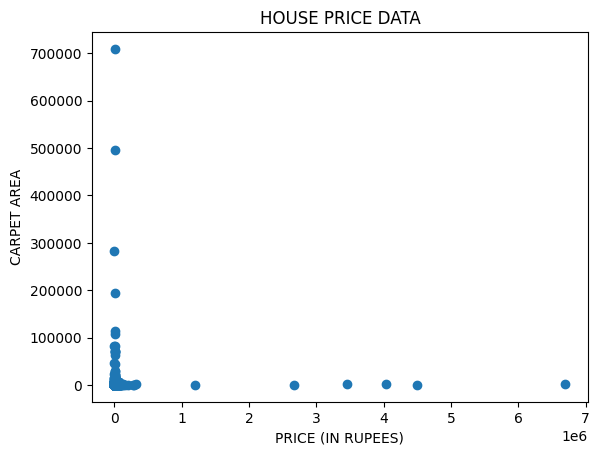

In [23]:
import matplotlib.pyplot as plt

plt.scatter(df["Price (in rupees)"],df["Carpet Area"])

plt.title("HOUSE PRICE DATA")
plt.xlabel("PRICE (IN RUPEES)")
plt.ylabel("CARPET AREA")

plt.show()

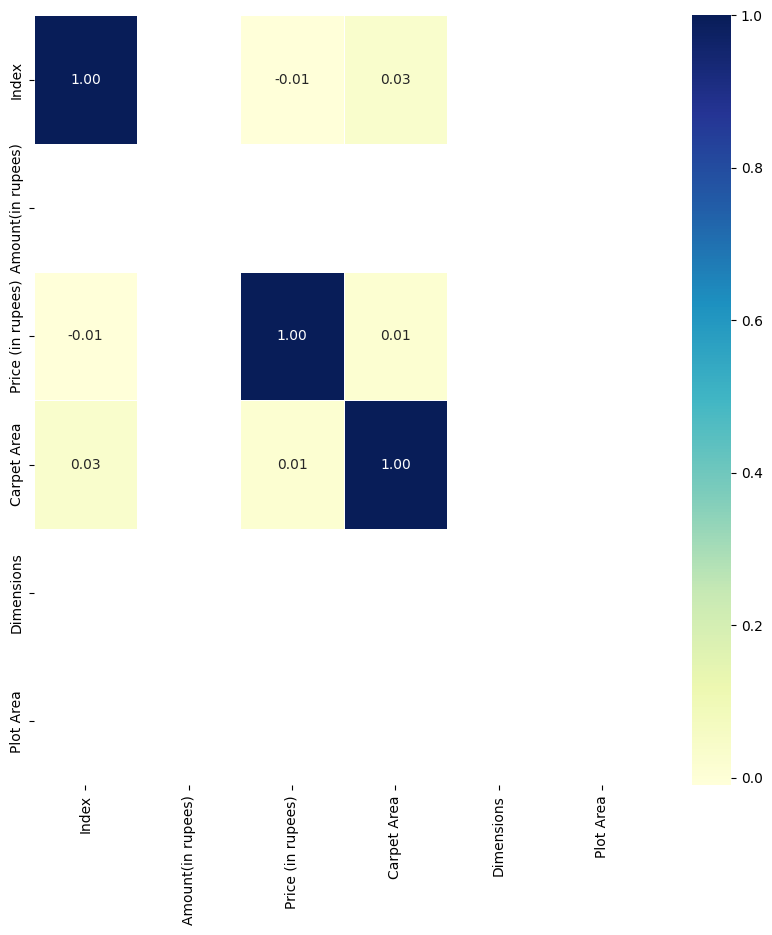

In [24]:
cor_map = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 10))

ax = sns.heatmap(
    cor_map,
    annot=True,
    linewidth=0.5,
    fmt="0.2f",
    cmap="YlGnBu"
)

plt.show()

In [ ]:
#x=df.drop(["Amount(in rupees)"],axis=1)
#y= df["Amount(in rupees)"]

In [ ]:

#x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=7)

In [ ]:
#len(x_train)

150024

In [ ]:
#len(y_train)

150024

In [54]:
len(y_test)

37507

In [55]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Define the model instances first
lr = LinearRegression()
KNN = KNeighborsRegressor()
RD = RandomForestRegressor()
XG = XGBRegressor()

# Now create the dictionary
model1 = {
    "Linear Regression": lr,
    "KNN Regression": KNN,
    "Random Forest": RD,
    "XGBoost": XG
}

In [60]:
# 1. Select numeric columns and target
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
target_col = 'Price (in rupees)'

# Exclude target and Index
features_to_use = [col for col in numeric_cols if col != target_col and col != 'Index']

# Extract x and y
x = df[features_to_use].copy()
y = df[target_col].copy()

# 2. Drop rows where the target price is missing
valid_rows = y.notnull()
x = x[valid_rows]
y = y[valid_rows]

# 3. CRITICAL: Drop columns that are 100% empty (all values are NaN)
x = x.dropna(axis=1, how='all')

# 4. Fill remaining missing values with the median of each column
x = x.fillna(x.median())

print("Cleaned feature columns used for training:", list(x.columns))

# 5. Split your data
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=7
)

# 6. Train your models directly using .fit()
for name, model in model1.items():
    model.fit(x_train, y_train)
    print(name, "trained successfully!")


Cleaned feature columns used for training: ['Carpet Area', 'Dimensions', 'Plot Area']
Linear Regression trained successfully!
KNN Regression trained successfully!
Random Forest trained successfully!
XGBoost trained successfully!


In [61]:
for name, model in model1.items():
    y_pred=model.predict(x_test)
    print(name, "PREDICT")

Linear Regression PREDICT
KNN Regression PREDICT
Random Forest PREDICT
XGBoost PREDICT


In [62]:
y_pred

array([6670.6694, 6455.9033, 6455.9033, ..., 2993.4036, 5797.16  ,
       6676.8633], shape=(37507,), dtype=float32)

In [63]:
for name, model in model1.items():
    score = model.score(x_test, y_test)
    print(name, "TEST:", score)

Linear Regression TEST: 0.0021698625445617514
KNN Regression TEST: -0.7045500788179384
Random Forest TEST: -2.450006369375866
XGBoost TEST: 0.07346092068572285


In [95]:
print("First 5 actual prices (y_test):", y_test.head().values)
print("First 5 predicted prices (y_pred):", y_pred[:5])

First 5 actual prices (y_test): [6189. 6729. 7949. 3840.    0.]
First 5 predicted prices (y_pred): [6670.6694 6455.9033 6455.9033 6455.9033 2347.759 ]


In [64]:
param_grids = {
    "Linear Regression": {
        'fit_intercept': [True, False]
    },
    "KNN Regression": {
        'n_neighbors': [3, 5, 7, 9],
        'weights': ['uniform', 'distance']
    },
    "Random Forest": {
        'n_estimators': [50, 100],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    },
    "XGBoost": {
        'n_estimators': [50, 100],
        'max_depth': [3, 5],
        'learning_rate': [0.01, 0.1]
    }
}

# 7. Perform GridSearchCV and train/tune each model
best_models = {}

for name, model in model1.items():
    print(f"\n--- Tuning {name} ---")
    
    # Get the parameter grid for the current model
    param_grid = param_grids[name]
    
    # Set up GridSearchCV (using 3-fold cross-validation to save time)
    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=3,
        scoring='r2',
        n_jobs=-1
    )
    
    # Fit the grid search to the training data
    grid_search.fit(x_train, y_train)
    
    # Save the best model found
    best_models[name] = grid_search.best_estimator_
    
    print(f"Best Parameters for {name}: {grid_search.best_params_}")
    print(f"Best CV R² Score: {grid_search.best_score_:.4f}")
    
    # Evaluate on the test set
    test_score = best_models[name].score(x_test, y_test)
    print(f"{name} TEST R² Score: {test_score}")


--- Tuning Linear Regression ---
Best Parameters for Linear Regression: {'fit_intercept': True}
Best CV R² Score: -0.0002
Linear Regression TEST R² Score: 0.0021698625445617514

--- Tuning KNN Regression ---
Best Parameters for KNN Regression: {'n_neighbors': 9, 'weights': 'uniform'}
Best CV R² Score: -0.0414
KNN Regression TEST R² Score: -0.17726489007013524

--- Tuning Random Forest ---
Best Parameters for Random Forest: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 50}
Best CV R² Score: -0.1363
Random Forest TEST R² Score: -2.4222909058145095

--- Tuning XGBoost ---
Best Parameters for XGBoost: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 50}
Best CV R² Score: 0.0065
XGBoost TEST R² Score: 0.07800147565919968


In [80]:
lr=mean_absolute_error(y_test,y_pred)
lr

2808.8447797280314

In [81]:
lr=mean_squared_error(y_test,y_pred)
lr


62029821.27860482

In [82]:
lr=r2_score(y_test,y_pred)
lr

0.07346092068572285

In [86]:
KNN = mean_absolute_error(y_test, y_pred)
KNN




2808.8447797280314

In [87]:
KNN = mean_squared_error(y_test, y_pred)
KNN

62029821.27860482

In [88]:
KNN=r2_score(y_test, y_pred)
KNN

0.07346092068572285

In [89]:
XG = mean_absolute_error(y_test, y_pred)
XG

2808.8447797280314

In [90]:
XG = mean_squared_error(y_test, y_pred)
XG

62029821.27860482

In [91]:
XG=r2_score(y_test, y_pred)
XG

0.07346092068572285

In [92]:
RG = mean_absolute_error(y_test, y_pred)
RG

2808.8447797280314

In [93]:
RG = mean_squared_error(y_test, y_pred)
RG

62029821.27860482

In [94]:
RG=r2_score(y_test, y_pred)
RG

0.07346092068572285

In [96]:
import pickle
import pandas as pd
from xgboost import XGBRegressor

xgboost_model = XGBRegressor(
    learning_rate=0.1, 
    max_depth=5, 
    n_estimators=50, 
    random_state=7
)


xgboost_model.fit(x_train, y_train)


y_pred_xgb = xgboost_model.predict(x_test)


predictions_df = pd.DataFrame({
    'Predicted_Price_Per_SqFt': y_pred_xgb
})


predictions_df.to_csv('xgboost_predicted_prices.csv', index=False)
print("XGBoost predicted price column saved successfully to CSV!")


with open('xgboost_model.pkl', 'wb') as file:
    pickle.dump(xgboost_model, file)

print("XGBoost model successfully saved using pickle as 'xgboost_model.pkl'!")

XGBoost predicted price column saved successfully to CSV!
XGBoost model successfully saved using pickle as 'xgboost_model.pkl'!


In [ ]:

with open('xgboost_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)


array([7023.6196, 6450.3335, 6450.3335, ..., 3686.9343, 5870.3906,
       6370.515 ], shape=(37507,), dtype=float32)